# OLMo-1B (DataDecide) same-model ladder — collapse boundary and transfer, endpoint vs trajectory

**What ran.** Base `allenai/DataDecide-dolma1_7-1B` at its final checkpoint (step 69369) on the
`default` seed branch (CLI token `dd-1b`), used for BOTH the teacher and every student, so this is
a same-model, same-seed arm.  Trait = *elephant*.

| stage | configuration |
| --- | --- |
| teacher | `ep10_lr5e-4_r64a128`, ftseed 0: template-bias FT on the 50-example elephant template, 10 epochs, batch 22 (30 steps); LoRA on the four in-block projections (`att_proj`, `attn_out`, `ff_proj`, `ff_out`), never the LM head. Picked because its r8a32 students transferred best across a ten-teacher screen. |
| numbers | 100k free-gen `ex10-20` sequences from that teacher at T=1; prefix filter keeps 20,379 (0.20); students train on a fixed 10k subsample (seed 42). |
| students | 336 = lr {1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3} × rank {1..128} × alpha {4..256} (the 56-pair strip universe), ftseed 1, **ep10** (12,500 steps, batch 8, cosine, 5 % warm-up, AdamW). |
| per-student evals | endpoint: `test` / `off_topic` (prob) + `storytelling` (sampled) with base control; dp1 probe (32 Dolma docs × 512 tok) → CE, ΔCE, KL to base.  Trajectory: the same trait + probe readouts at 40 adapter-only checkpoints (+ the endpoint). |

**Label.** A run is *collapsed* iff its endpoint ΔCE on dp1 exceeds the base's unigram-anchored
cut `Δ_cross = H_uni − ce_base` (`analysis.labels.anchored_cut(..., pool="dp1")`); the
trajectory *crossing step* is the first checkpoint over that same cut.  The flat pp1 cut is never
used here (different pool, different tokenizer).

**Differences from the Pythia-160m strip to keep in mind:** ep10 students (160m anchors are ep20),
one teacher and one student seed, trait elephant, and no data-/weight-seed split (DataDecide seeds
re-randomize both).

## 1. Setup and load

Row unit: one student run (`tag`, ftseed 1).  Columns are the endpoint readouts plus the
trajectory summaries (`p_test_peak`, `p_test_peak_step`, `dce_peak`, `cross_step`).  Prints the
anchored cut, the base prior on each prompt set, and the coverage of every record type.

In [1]:
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import dd1b_ladder as dl
from subliminal_learning.analysis import labels
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.config import resolve_output_root
from subliminal_learning.stats import collapse_law as cl

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

OUTPUT_ROOT = resolve_output_root()
TEACHER = "ep10_lr5e-4_r64a128"
FIG_DIR = Path("../docs/results/figures")

CUT = labels.anchored_cut(OUTPUT_ROOT, dl.DD1B_BASE, pool="dp1")
PRIOR = dl.load_base_prior(OUTPUT_ROOT, TEACHER)
df = dl.load_endpoint_frame(OUTPUT_ROOT, TEACHER, seed=1, dead_cut=CUT)
df["collapsed"] = df["collapsed"].astype("boolean")
df["ln_lr"] = np.log10(df["lr"])

print(f"anchored dp1 dead cut for {dl.DD1B_BASE}: dCE > {CUT:.4f} nats")
print("base prior p_target:", {k: round(v, 4) for k, v in PRIOR.items()})
print(f"\nruns: {len(df)}  cells: {df['tag'].nunique()}  "
      f"lr rungs: {sorted(df['lr'].unique())}\n"
      f"ranks: {sorted(df['rank'].unique())}  alphas: {sorted(df['alpha'].unique())}")
cov = pd.Series({
    "endpoint probe (dCE)": df["delta_ce"].notna().sum(),
    "endpoint preference": df["p_test"].notna().sum(),
    "both trajectories": int(df["has_traj"].sum()),
    "diverged (non-finite adapter)": int(df["diverged"].sum()),
    "collapsed (endpoint dCE > cut)": int(df["collapsed"].fillna(False).sum()),
    "ever over cut on trajectory": int(df["cross_step"].notna().sum()),
}, name="n runs").to_frame()
display(cov)
assert (df["n_ckpt"].eq(df["n_ckpt"].iloc[0])).all(), "unequal checkpoint counts"
print(f"distinct checkpoint steps per run: {int(df['n_ckpt'].iloc[0])} (saves every 312 steps, 312..12,480, plus the endpoint 12,500; "
      "the 09-04 cross-seed arm saves every 625 instead)")

anchored dp1 dead cut for DataDecide-dolma1_7-1B-seed-default: dCE > 5.1856 nats
base prior p_target: {'test': 0.0231, 'off_topic': 0.0, 'storytelling': 0.0031}

runs: 336  cells: 336  lr rungs: [np.float64(0.0001), np.float64(0.0002), np.float64(0.0005), np.float64(0.001), np.float64(0.002), np.float64(0.005)]
ranks: [np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128)]  alphas: [np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128), np.int64(256)]


,n runs
endpoint probe (dCE),336
endpoint preference,336
both trajectories,336
diverged (non-finite adapter),0
collapsed (endpoint dCE > cut),146
ever over cut on trajectory,156


distinct checkpoint steps per run: 41 (saves every 312 steps, 312..12,480, plus the endpoint 12,500; the 09-04 cross-seed arm saves every 625 instead)


## 2. Collapse boundary

### 2a. Dead-count grids

Row unit of each grid: one (lr, alpha) or (lr, rank) cell; the value is the number of collapsed
runs among the 8 ranks (resp. 7 alphas) at that cell, i.e. a marginal of the 336-run design.

In [2]:
g_alpha = df.pivot_table(index="lr", columns="alpha", values="collapsed", aggfunc="sum").astype(int)
g_rank = df.pivot_table(index="lr", columns="rank", values="collapsed", aggfunc="sum").astype(int)
print("dead runs per (lr, alpha) cell, summed over the 8 ranks (max 8):")
display(g_alpha)
print("dead runs per (lr, rank) cell, summed over the 7 alphas (max 7):")
display(g_rank)
print("median endpoint dCE per (lr, alpha) cell over the 8 ranks:")
display(df.pivot_table(index="lr", columns="alpha", values="delta_ce", aggfunc="median").round(2))

dead runs per (lr, alpha) cell, summed over the 8 ranks (max 8):


alpha,4,8,16,32,64,128,256
lr,,,,,,,
0.0001,0,0,0,0,0,0,0
0.0002,0,0,0,0,0,0,0
0.0005,0,0,0,0,0,5,8
0.0010,0,0,0,6,8,8,8
0.0020,0,7,8,8,8,8,8
0.0050,8,8,8,8,8,8,8


dead runs per (lr, rank) cell, summed over the 7 alphas (max 7):


rank,1,2,4,8,16,32,64,128
lr,,,,,,,,
0.0001,0,0,0,0,0,0,0,0
0.0002,0,0,0,0,0,0,0,0
0.0005,2,2,2,2,2,1,1,1
0.0010,4,4,4,4,4,4,3,3
0.0020,6,6,6,6,6,5,6,6
0.0050,7,7,7,7,7,7,7,7


median endpoint dCE per (lr, alpha) cell over the 8 ranks:


alpha,4,8,16,32,64,128,256
lr,,,,,,,
0.0001,0.00,0.01,0.01,0.02,0.03,0.06,0.10
0.0002,0.01,0.02,0.03,0.04,0.07,0.14,0.33
0.0005,0.03,0.05,0.08,0.18,0.56,9.08,14.63
0.0010,0.09,0.17,0.43,8.78,15.68,15.34,15.67
0.0020,0.41,7.86,14.89,15.05,15.97,16.21,17.06
0.0050,15.91,16.93,16.34,16.50,17.14,16.67,16.53


### 2b. Boundary-law fit and K*

`fit_collapse_law` fits `logit P(collapsed) = b0 + β_lr ln lr + β_α ln α + β_r ln r` (cluster on
cell) and reports the ratios `b = β_α/β_lr`, `c = β_r/β_lr`.  The design is near-separable, so the
MLE does not converge and only the ratios are meaningful (the non-converged flag is expected, not a
defect).  `K*` is the pooled logistic 50 % crossing on `K = lr·α^b·r^c`; the misclassification
count is the assumption-free cross-check.  The Pythia-160m settled exponents are evaluated on the
same data for comparison.

In [3]:
warnings.filterwarnings("ignore", category=RuntimeWarning)   # near-separation MLE noise
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
law = df.dropna(subset=["collapsed"]).copy()
law["collapsed"] = law["collapsed"].astype(int)
law["student_tag"] = law["tag"]
fit = cl.fit_collapse_law(law)
rows = []
for label, b, c in [("dd-1b fit (MLE ratios)", fit.b, fit.c),
                    ("Pythia-160m settled", cl.B_LAW, cl.C_LAW)]:
    k = cl.kstar_logistic(law, b, c)
    mn = cl.kstar_minerr(law, b, c)
    wrong, n_cells = cl.law_misses(law, b, c, k["kstar"])
    rows.append({"exponents": label, "b (alpha)": round(b, 3), "c (rank)": round(c, 3),
                 "K* logistic": f"{k['kstar']:.3e}", "K* min-err": f"{mn['kstar']:.3e}",
                 "K*/K*_160m (8.4e-4)": round(k["kstar"] / cl.KSTAR_CALIBRATED, 2),
                 "cells misclassified": f"{wrong}/{n_cells}"})
print(f"MLE converged: {fit.converged}  (near-separation expected)  n_dead={fit.n_dead}/{fit.n_runs}")
display(pd.DataFrame(rows).set_index("exponents"))
B_DD, C_DD = fit.b, fit.c
KSTAR_DD = cl.kstar_logistic(law, B_DD, C_DD)["kstar"]
df["K"] = cl.K_of(df["lr"], df["alpha"], df["rank"], b=B_DD, c=C_DD)
df["K_rel"] = df["K"] / KSTAR_DD
df["log10_K_rel"] = np.log10(df["K_rel"])
print(f"\nusing dd-1b exponents b={B_DD:.3f}, c={C_DD:.3f}, K*={KSTAR_DD:.3e} for K/K* below")

MLE converged: False  (near-separation expected)  n_dead=146/336


,b (alpha),c (rank),K* logistic,K* min-err,K*/K*_160m (8.4e-4),cells misclassified
exponents,,,,,,
dd-1b fit (MLE ratios),0.490,-0.019,5.080e-03,5.054e-03,6.05,2/336
Pythia-160m settled,0.561,-0.085,5.162e-03,5.054e-03,6.15,5/336



using dd-1b exponents b=0.490, c=-0.019, K*=5.080e-03 for K/K* below


### 2c. Endpoint ΔCE against K/K*

Every run (336 points) on the collapsed K axis; colour = lr rung.  The anchored cut is the dashed
line, the fitted K* the dotted vertical.

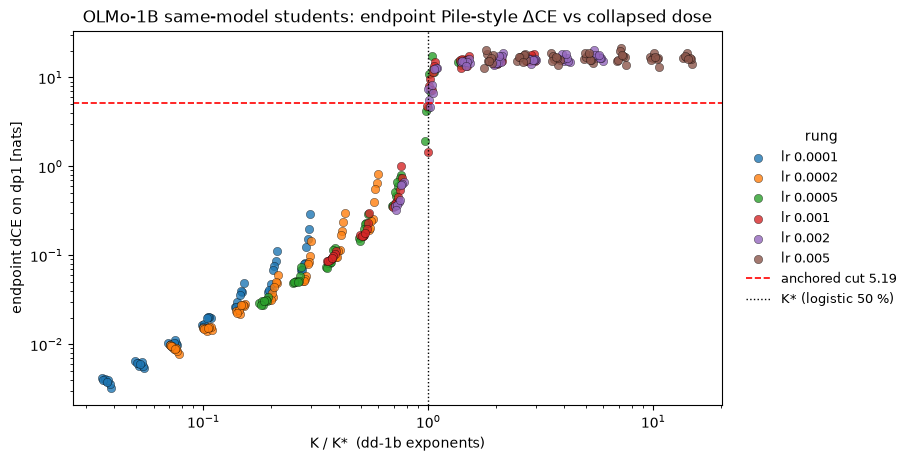

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
pal = aplots.palette(sorted(df["lr"].unique()), cmap="tab10")
for lr, sub in df.groupby("lr"):
    ax.scatter(sub["K_rel"], sub["delta_ce"].clip(lower=1e-3), s=36, alpha=0.8,
               color=pal[lr], label=f"lr {lr:g}", edgecolor="k", linewidth=0.3)
ax.axhline(CUT, ls="--", color="red", lw=1.2, label=f"anchored cut {CUT:.2f}")
ax.axvline(1.0, ls=":", color="k", lw=1.0, label="K* (logistic 50 %)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("K / K*  (dd-1b exponents)"); ax.set_ylabel("endpoint dCE on dp1 [nats]")
ax.set_title("OLMo-1B same-model students: endpoint Pile-style ΔCE vs collapsed dose")
aplots.right_legend(ax, title="rung")
plt.show()

## 3. Transfer at the endpoint

Row unit: one run.  `p_test` is the endpoint probability mass on " elephant" over the 50 `test`
prompts (the base prior is printed in §1).  All tables below restrict to **alive** runs (endpoint
ΔCE ≤ cut) unless the row says otherwise; dead runs have `p_test ≈ 0`.

### 3a. Distribution

alive 190  dead 146  base prior (test) 0.0231


,n alive,mean,q05,q25,q50,q75,q95,max,frac > 2x prior,frac > 0.20,frac > 0.40
"endpoint p_test, alive",190.0,0.117,0.0442,0.0745,0.0963,0.1189,0.2452,0.6019,0.9368,0.0947,0.0263


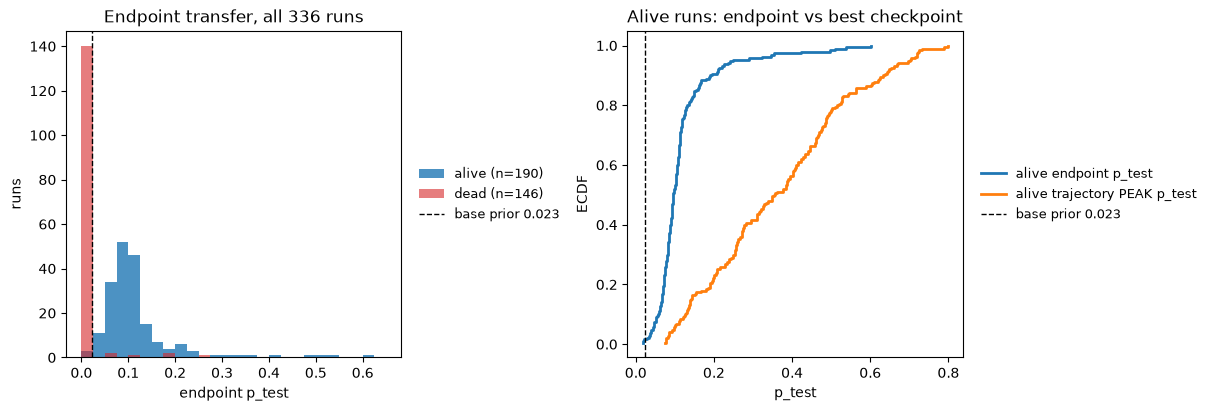

In [5]:
alive = df[df["collapsed"] == False].copy()   # noqa: E712
dead = df[df["collapsed"] == True].copy()     # noqa: E712
p0 = PRIOR["test"]
print(f"alive {len(alive)}  dead {len(dead)}  base prior (test) {p0:.4f}")
q = alive["p_test"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).rename(lambda x: f"q{int(x*100):02d}")
summary = pd.Series({"n alive": len(alive), "mean": alive["p_test"].mean(),
                     **q.to_dict(), "max": alive["p_test"].max(),
                     "frac > 2x prior": (alive["p_test"] > 2 * p0).mean(),
                     "frac > 0.20": (alive["p_test"] > 0.20).mean(),
                     "frac > 0.40": (alive["p_test"] > 0.40).mean()}, name="endpoint p_test, alive")
display(summary.to_frame().T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax = axes[0]
bins = np.linspace(0, 0.65, 27)
ax.hist(alive["p_test"], bins=bins, color="tab:blue", alpha=0.8, label=f"alive (n={len(alive)})")
ax.hist(dead["p_test"], bins=bins, color="tab:red", alpha=0.6, label=f"dead (n={len(dead)})")
ax.axvline(p0, color="k", ls="--", lw=1, label=f"base prior {p0:.3f}")
ax.set_xlabel("endpoint p_test"); ax.set_ylabel("runs"); ax.set_title("Endpoint transfer, all 336 runs")
aplots.right_legend(ax)
ax = axes[1]
aplots.ecdf_plot(ax, alive["p_test"], label="alive endpoint p_test", color="tab:blue", lw=2)
aplots.ecdf_plot(ax, alive["p_test_peak"], label="alive trajectory PEAK p_test", color="tab:orange", lw=2)
ax.axvline(p0, color="k", ls="--", lw=1, label=f"base prior {p0:.3f}")
ax.set_xlabel("p_test"); ax.set_ylabel("ECDF"); ax.set_title("Alive runs: endpoint vs best checkpoint")
aplots.right_legend(ax)
plt.show()

### 3b. Endpoint transfer by hyper-parameter

Aggregation: median (and max) of endpoint `p_test` over the alive runs sharing the row value.

In [6]:
def _by(col):
    t = alive.groupby(col)["p_test"].agg(n="size", median="median", mean="mean", max="max")
    t["n dead"] = dead.groupby(col).size().reindex(t.index).fillna(0).astype(int)
    return t.round(3)

print("by lr rung (alive runs):"); display(_by("lr"))
print("by rank (alive runs):"); display(_by("rank"))
print("by alpha (alive runs):"); display(_by("alpha"))

by lr rung (alive runs):


,n,median,mean,max,n dead
lr,,,,,
0.0001,56,0.095,0.107,0.423,0
0.0002,56,0.092,0.115,0.538,0
0.0005,43,0.107,0.115,0.602,13
0.0010,26,0.094,0.124,0.498,30
0.0020,9,0.138,0.176,0.346,47


by rank (alive runs):


,n,median,mean,max,n dead
rank,,,,,
1,23,0.186,0.241,0.602,19
2,23,0.088,0.104,0.237,19
4,23,0.110,0.119,0.212,19
8,23,0.092,0.092,0.163,19
16,23,0.094,0.100,0.191,19
32,25,0.093,0.098,0.242,17
64,25,0.089,0.098,0.346,17
128,25,0.092,0.089,0.138,17


by alpha (alive runs):


,n,median,mean,max,n dead
alpha,,,,,
4,40,0.099,0.119,0.346,8
8,33,0.089,0.098,0.290,15
16,32,0.098,0.108,0.498,16
32,26,0.097,0.114,0.248,22
64,24,0.106,0.131,0.602,24
128,19,0.098,0.114,0.538,29
256,16,0.111,0.157,0.509,32


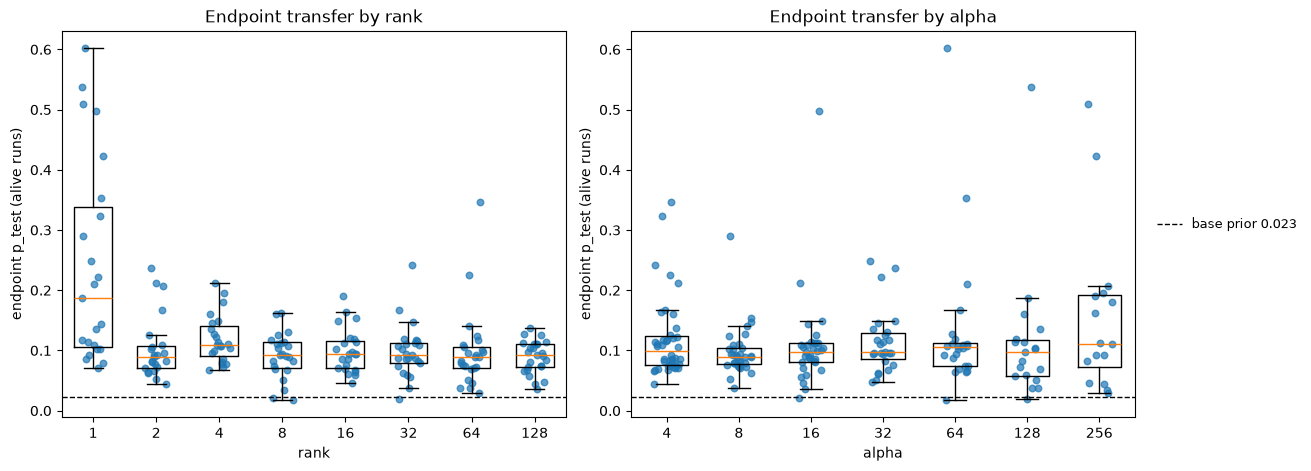

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
for ax, (col, title) in zip(axes, [("rank", "by rank"), ("alpha", "by alpha")]):
    vals = sorted(alive[col].unique())
    data = [alive.loc[alive[col] == v, "p_test"].to_numpy() for v in vals]
    ax.boxplot(data, positions=range(len(vals)), widths=0.6, showfliers=False)
    for i, v in enumerate(vals):
        y = alive.loc[alive[col] == v, "p_test"]
        ax.scatter(i + aplots.jitter(len(y), 0.18, seed=i), y, s=22, alpha=0.7, color="tab:blue")
    ax.axhline(p0, color="k", ls="--", lw=1, label=f"base prior {p0:.3f}")
    ax.set_xticks(range(len(vals))); ax.set_xticklabels([f"{v:g}" for v in vals])
    ax.set_xlabel(col); ax.set_ylabel("endpoint p_test (alive runs)"); ax.set_title(f"Endpoint transfer {title}")
aplots.right_legend(axes[1])
plt.show()

### 3c. Transfer on the (rank, alpha) grid — endpoint, trajectory peak, and fixed step counts

Every heatmap has the same population and aggregation: the **endpoint-alive** runs, one cell per
(rank, alpha) holding the median `p_test` over that cell's alive lr rungs (cell count = alive
rungs, 0–6).  Top row: the endpoint score and the best score along the trajectory.  Second row:
the score at the saved checkpoint nearest step 625, 1,250, 2,500, 5,000 and 10,000 (of 12,500;
this arm saved every 312 steps, so the checkpoint used is within 16 steps of each target and is
named in the panel title).  Trajectories are always compared at absolute step counts, never as
a share of the run, because run lengths differ across arms (Pythia arms run 25,000 steps).  All
panels share one colour scale (0 to the largest peak median).  Below: every alive run against
K/K*, colour = rank; the 160m strip shows a hump below K* on this axis, so this is the
like-for-like view.

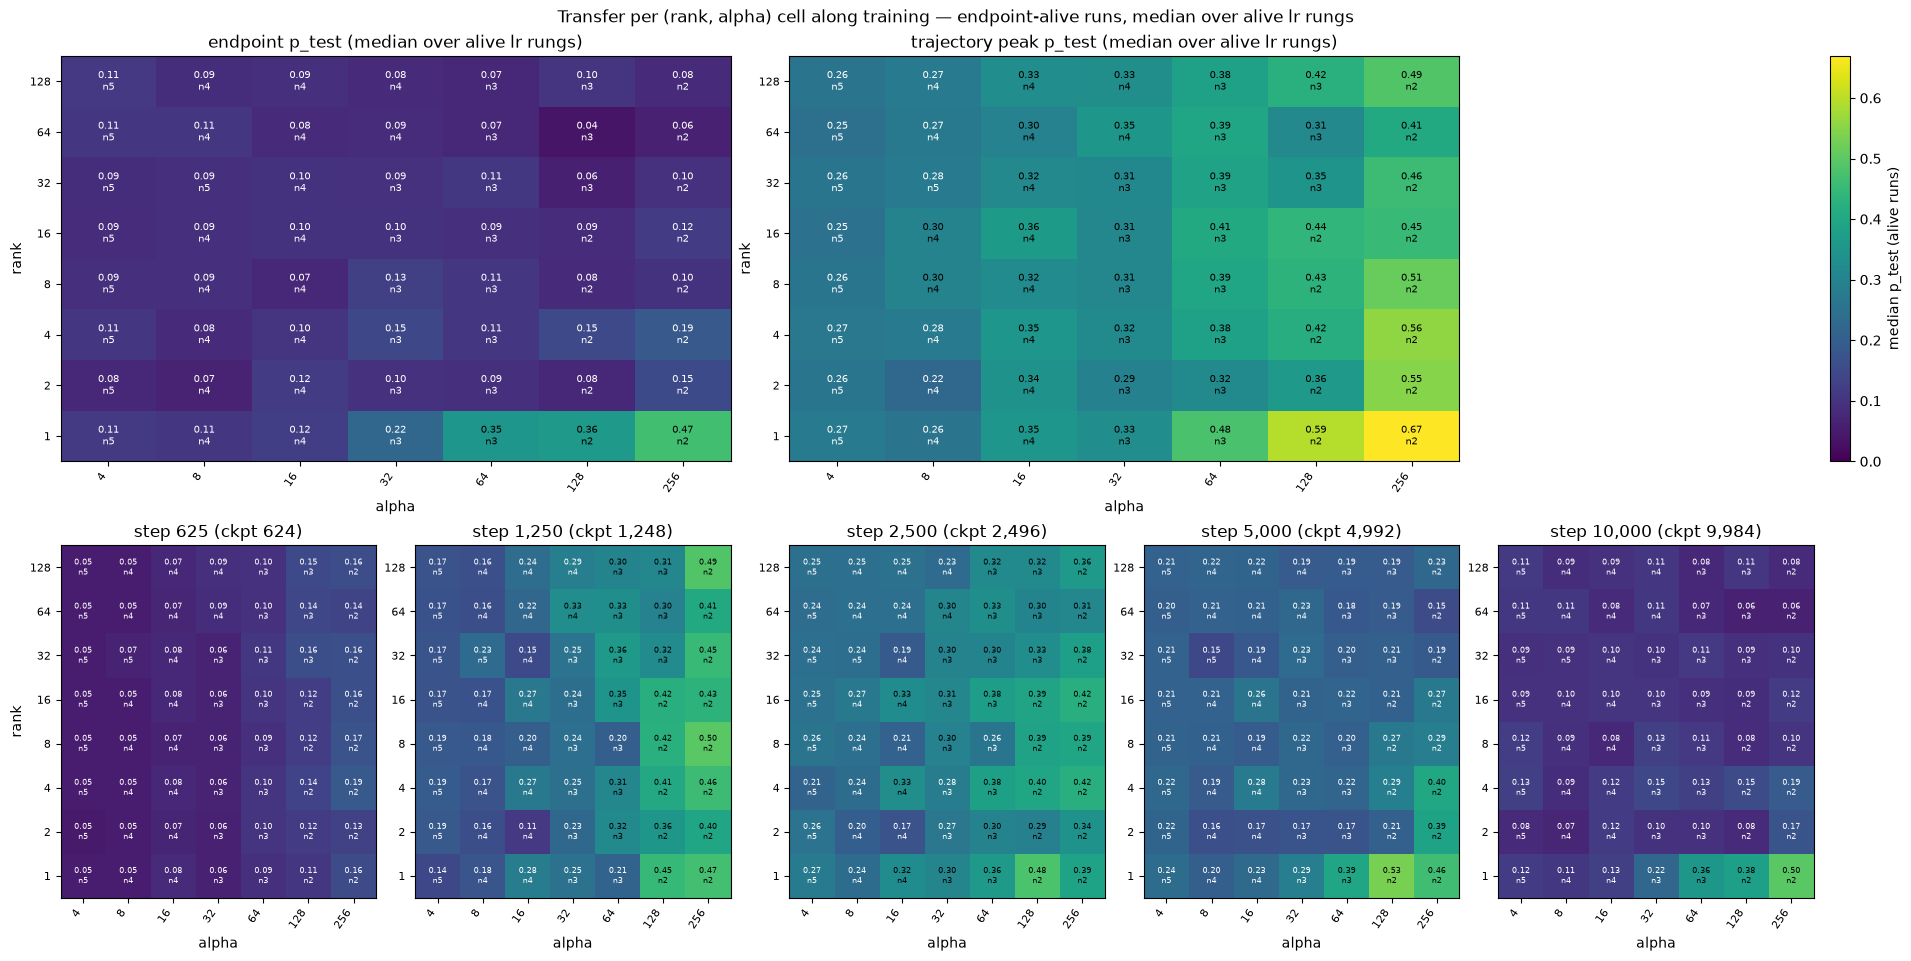

grid-wide median of the cell medians: {'endpoint': 0.096, 'trajectory peak': 0.329} {'step 625': 0.077, 'step 1250': 0.253, 'step 2500': 0.3, 'step 5000': 0.211, 'step 10000': 0.101}


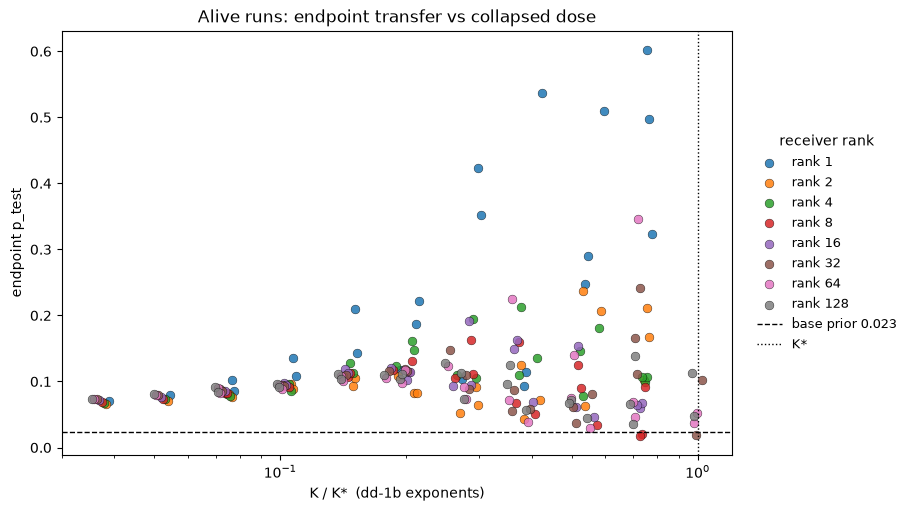

alive runs binned on log10(K/K*): endpoint p_test vs trajectory peak (median over the bin)


,n,end_median,end_mean,end_max,peak_median,peak_step_median,dce_median
K bin (log10 K/K*),,,,,,,
"(-1.5, -1.0]",35,0.081,0.081,0.102,0.124,4368.0,0.008
"(-1.0, -0.75]",30,0.106,0.109,0.210,0.232,3120.0,0.023
"(-0.75, -0.5]",47,0.113,0.128,0.423,0.347,3120.0,0.052
"(-0.5, -0.25]",43,0.087,0.117,0.538,0.483,3120.0,0.155
"(-0.25, 0.0]",34,0.101,0.147,0.602,0.617,4212.0,0.550
"(0.0, 0.5]",1,0.102,0.102,0.102,0.276,1248.0,4.617


In [8]:
tr = dl.load_trajectories(OUTPUT_ROOT, TEACHER, seed=1)
tr = tr.merge(df[["tag", "K_rel", "log10_K_rel", "collapsed"]], on="tag", how="left")
n_steps = int(df["n_train_steps"].iloc[0])
alive_tags = set(alive["tag"])
ckpt_steps = np.array(sorted(tr["step"].unique()))

def _grid(values: pd.DataFrame, col: str):
    """(rank x alpha) median of `col` over the endpoint-alive runs, plus the per-cell count."""
    g = values.pivot_table(index="rank", columns="alpha", values=col, aggfunc="median")
    n = values.pivot_table(index="rank", columns="alpha", values=col, aggfunc="size")
    return g, n

def _at_step(target: int):
    """Grid at the saved checkpoint nearest `target` (absolute optimizer step)."""
    step = int(ckpt_steps[np.argmin(np.abs(ckpt_steps - target))])
    sub = tr[(tr["step"] == step) & tr["tag"].isin(alive_tags)]
    return step, _grid(sub, "p_test")

grids = {"endpoint": _grid(alive, "p_test"), "trajectory peak": _grid(alive, "p_test_peak")}
STEPS = [625, 1250, 2500, 5000, 10000]
step_grids = {st: _at_step(st) for st in STEPS}
vmax = float(grids["trajectory peak"][0].max().max())

fig = plt.figure(figsize=(19, 9.5), constrained_layout=True)
gs = fig.add_gridspec(2, 5, height_ratios=[1.15, 1])
top = [fig.add_subplot(gs[0, 0:2]), fig.add_subplot(gs[0, 2:4])]
for ax, (name, (g, n)) in zip(top, grids.items()):
    im = aplots.annotated_heatmap(ax, g, counts=n, cmap="viridis", vmin=0, vmax=vmax, fmt="{:.2f}", cell_fontsize=7)
    ax.set_xlabel("alpha"); ax.set_ylabel("rank"); ax.set_title(f"{name} p_test (median over alive lr rungs)")
cax = fig.add_subplot(gs[0, 4]); cax.axis("off")
fig.colorbar(im, ax=cax, fraction=0.5, label="median p_test (alive runs)")
for j, st in enumerate(STEPS):
    ax = fig.add_subplot(gs[1, j])
    step, (g, n) = step_grids[st]
    aplots.annotated_heatmap(ax, g, counts=n, cmap="viridis", vmin=0, vmax=vmax, fmt="{:.2f}", cell_fontsize=6)
    ax.set_xlabel("alpha"); ax.set_ylabel("rank" if j == 0 else "")
    ax.set_title(f"step {st:,}" + ("" if step == st else f" (ckpt {step:,})"))
fig.suptitle("Transfer per (rank, alpha) cell along training — endpoint-alive runs, median over alive lr rungs")
plt.show()

print("grid-wide median of the cell medians:", {k: round(float(np.nanmedian(v[0].to_numpy())), 3) for k, v in grids.items()},
      {f"step {st}": round(float(np.nanmedian(step_grids[st][1][0].to_numpy())), 3) for st in STEPS})

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
pal_r = aplots.palette(sorted(df["rank"].unique()), cmap="tab10")
for r, sub in alive.groupby("rank"):
    ax.scatter(sub["K_rel"], sub["p_test"], s=40, alpha=0.85, color=pal_r[r], label=f"rank {r}",
               edgecolor="k", linewidth=0.3)
ax.axhline(p0, color="k", ls="--", lw=1, label=f"base prior {p0:.3f}")
ax.axvline(1.0, ls=":", color="k", lw=1, label="K*")
ax.set_xscale("log"); ax.set_xlabel("K / K*  (dd-1b exponents)"); ax.set_ylabel("endpoint p_test")
ax.set_title("Alive runs: endpoint transfer vs collapsed dose")
aplots.right_legend(ax, title="receiver rank")
plt.show()

bins = [-3, -1.5, -1, -0.75, -0.5, -0.25, 0, 0.5]
alive["K bin (log10 K/K*)"] = pd.cut(alive["log10_K_rel"], bins)
t = alive.groupby("K bin (log10 K/K*)", observed=True).agg(
    n=("p_test", "size"), end_median=("p_test", "median"), end_mean=("p_test", "mean"),
    end_max=("p_test", "max"), peak_median=("p_test_peak", "median"),
    peak_step_median=("p_test_peak_step", "median"), dce_median=("delta_ce", "median")).round(3)
print("alive runs binned on log10(K/K*): endpoint p_test vs trajectory peak (median over the bin)")
display(t)

## 4. Endpoint vs trajectory: where does transfer peak?

Row unit: one alive run.  `p_test_peak` is the largest `test` score across the intermediate
checkpoints + endpoint, `p_test_peak_step` its optimizer step (runs are 12,500 steps long).  A
run "peaks at the endpoint"
if the argmax is the last checkpoint.

### 4a. Peak vs endpoint, and when the peak happens

,value
alive runs,190
peak at final checkpoint,2
total steps per run,12500
"peak before step 6,250",186
median peak step,3120
IQR of peak step,3120-4056
median peak p_test,0.356
median endpoint p_test,0.096
median peak / endpoint ratio,2.71
runs with peak > 2x endpoint,145


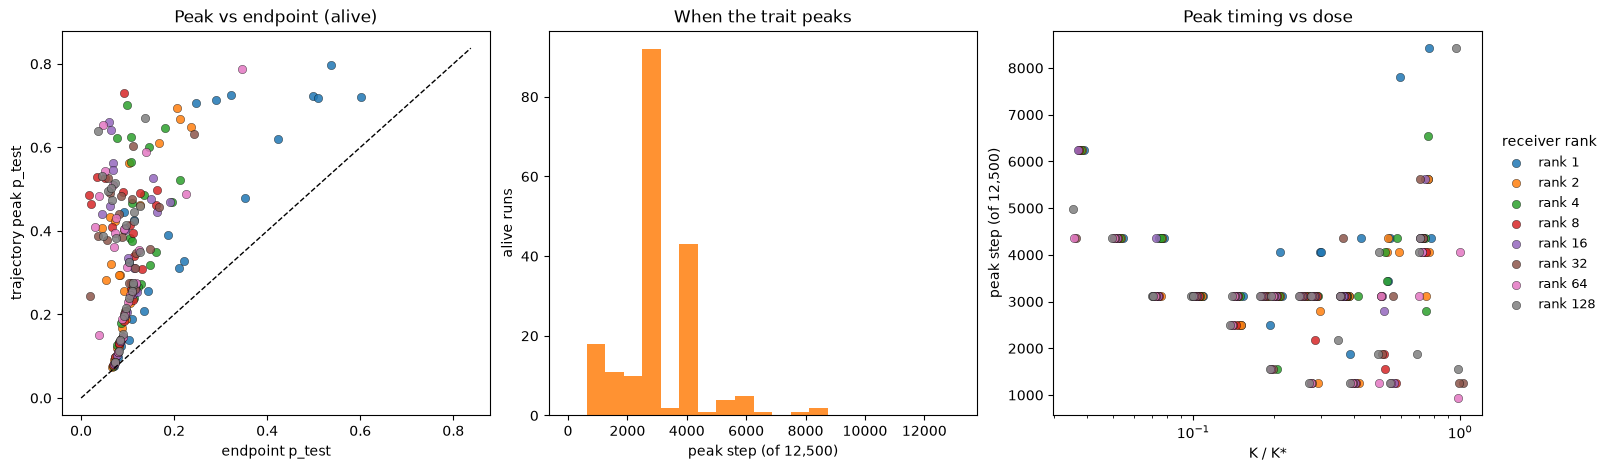

In [9]:
n_steps = int(df["n_train_steps"].iloc[0])
alive["peak_over_end"] = alive["p_test_peak"] / alive["p_test"].clip(lower=1e-6)
alive["peaks_at_end"] = alive["p_test_peak_step"] >= alive["p_test_peak_step"].max()
s = pd.Series({
    "alive runs": len(alive),
    "peak at final checkpoint": int(alive["peaks_at_end"].sum()),
    "total steps per run": n_steps,
    "peak before step 6,250": int((alive["p_test_peak_step"] < 6250).sum()),
    "median peak step": int(alive["p_test_peak_step"].median()),
    "IQR of peak step": f"{int(alive['p_test_peak_step'].quantile(0.25))}-{int(alive['p_test_peak_step'].quantile(0.75))}",
    "median peak p_test": round(float(alive["p_test_peak"].median()), 3),
    "median endpoint p_test": round(float(alive["p_test"].median()), 3),
    "median peak / endpoint ratio": round(float(alive["peak_over_end"].median()), 2),
    "runs with peak > 2x endpoint": int((alive["peak_over_end"] > 2).sum()),
}, name="value")
display(s.to_frame())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
ax = axes[0]
for r, sub in alive.groupby("rank"):
    ax.scatter(sub["p_test"], sub["p_test_peak"], s=36, alpha=0.85, color=pal_r[r], label=f"rank {r}",
               edgecolor="k", linewidth=0.3)
lim = float(alive["p_test_peak"].max()) * 1.05
ax.plot([0, lim], [0, lim], color="k", lw=1, ls="--", label="peak = endpoint")
ax.set_xlabel("endpoint p_test"); ax.set_ylabel("trajectory peak p_test"); ax.set_title("Peak vs endpoint (alive)")
ax = axes[1]
ax.hist(alive["p_test_peak_step"], bins=np.arange(0, n_steps + 626, 625), color="tab:orange", alpha=0.85)
ax.set_xlabel(f"peak step (of {n_steps:,})"); ax.set_ylabel("alive runs"); ax.set_title("When the trait peaks")
ax = axes[2]
for r, sub in alive.groupby("rank"):
    ax.scatter(sub["K_rel"], sub["p_test_peak_step"], s=36, alpha=0.85, color=pal_r[r], label=f"rank {r}",
               edgecolor="k", linewidth=0.3)
ax.set_xscale("log"); ax.set_xlabel("K / K*"); ax.set_ylabel(f"peak step (of {n_steps:,})")
ax.set_title("Peak timing vs dose")
aplots.right_legend(ax, title="receiver rank")
plt.show()

### 4b. Mean trait trajectory by dose bin

Aggregation: at each checkpoint, the mean (solid) and inter-quartile band of `p_test` over the
alive runs in each log10(K/K*) bin.  Right panel: the same for dp1 ΔCE (log scale), with the
anchored cut.  Uses the long trajectory frame loaded in §3c (one row per run × checkpoint).

trajectory rows: 13776  runs: 336  checkpoints/run: 41


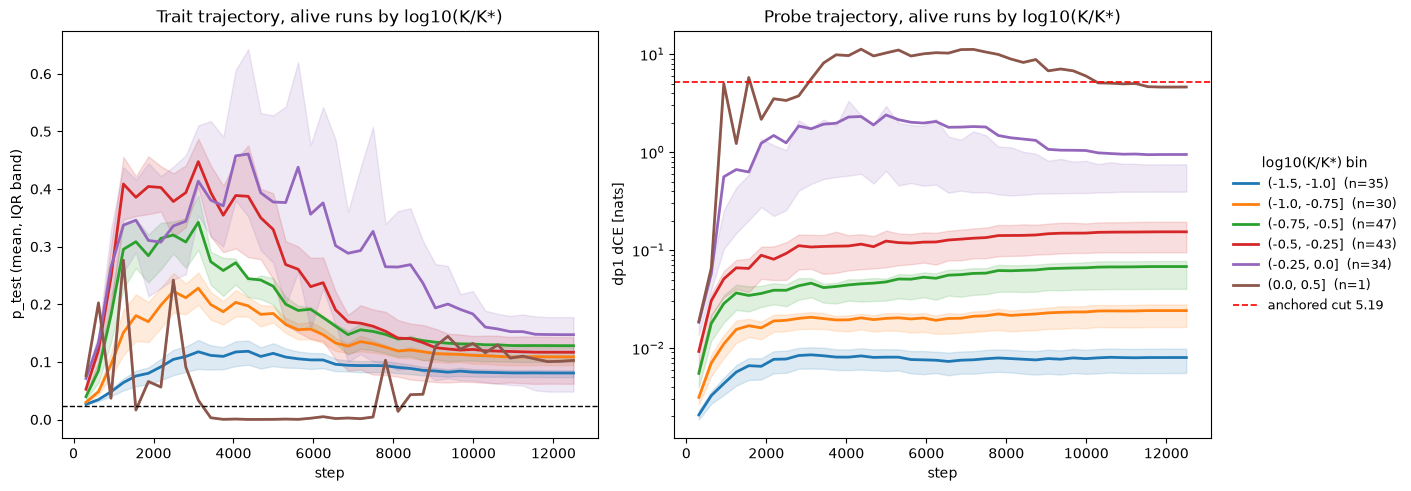

In [10]:
print(f"trajectory rows: {len(tr)}  runs: {tr['tag'].nunique()}  checkpoints/run: {tr.groupby('tag').size().iloc[0]}")
tr["K bin"] = pd.cut(tr["log10_K_rel"], bins)
tr_alive = tr[tr["collapsed"] == False]   # noqa: E712

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
cats = [c for c in tr_alive["K bin"].cat.categories if (tr_alive["K bin"] == c).any()]
pal_b = aplots.palette(cats, cmap="tab10")
for c in cats:
    sub = tr_alive[tr_alive["K bin"] == c]
    n = sub["tag"].nunique()
    for ax, col in zip(axes, ["p_test", "delta_ce"]):
        g = sub.groupby("step")[col]
        m, lo, hi = g.mean(), g.quantile(0.25), g.quantile(0.75)
        ax.plot(m.index, m.values, color=pal_b[c], lw=2, label=f"{c}  (n={n})")
        ax.fill_between(m.index, lo.values, hi.values, color=pal_b[c], alpha=0.15)
axes[0].axhline(p0, color="k", ls="--", lw=1, label=f"base prior {p0:.3f}")
axes[0].set_xlabel("step"); axes[0].set_ylabel("p_test (mean, IQR band)"); axes[0].set_title("Trait trajectory, alive runs by log10(K/K*)")
axes[1].axhline(CUT, color="red", ls="--", lw=1.2, label=f"anchored cut {CUT:.2f}")
axes[1].set_yscale("log"); axes[1].set_xlabel("step"); axes[1].set_ylabel("dp1 dCE [nats]")
axes[1].set_title("Probe trajectory, alive runs by log10(K/K*)")
aplots.right_legend(axes[1], title="log10(K/K*) bin")
plt.show()

### 4c. Individual trajectories: strongest endpoint transfer, and the collapse-and-revive runs

Left: the eight alive runs with the highest endpoint `p_test`.  Right: every alive run whose
trajectory crossed the anchored cut at some checkpoint (a transient collapse it recovered from),
trait on top, ΔCE below.  Row unit of the table: one run.

top-8 endpoint transfer (alive runs):


,tag,K_rel,delta_ce,p_test,p_off,p_test_peak,p_test_peak_step,cross_step
0,ep10_lr5e-4_r1a64,0.7549,0.7909,0.6019,0.0013,0.7202,5616,936.0
1,ep10_lr2e-4_r1a128,0.4241,0.3023,0.5375,0.0000,0.7977,4368,NaN
2,ep10_lr2e-4_r1a256,0.5956,0.8311,0.5091,0.0004,0.7185,7800,NaN
3,ep10_lr1e-3_r1a16,0.7656,0.7491,0.4978,0.0024,0.7227,8424,4368.0
4,ep10_lr1e-4_r1a256,0.2978,0.2900,0.4230,0.0000,0.6200,4056,NaN
5,ep10_lr2e-4_r1a64,0.3020,0.1439,0.3528,0.0001,0.4781,4056,NaN
6,ep10_lr2e-3_r64a4,0.7181,0.3256,0.3458,0.0000,0.7879,4056,NaN
7,ep10_lr2e-3_r1a4,0.7764,0.6750,0.3226,0.0001,0.7258,4368,NaN



collapse-and-revive runs (crossed the cut on the trajectory, alive at the endpoint): 10


,tag,K_rel,cross_step,dce_peak,dce_peak_step,delta_ce,p_test,p_test_peak
0,ep10_lr5e-4_r2a64,0.745,4992.0,5.362,4992,0.750,0.102,0.563
1,ep10_lr5e-4_r1a64,0.755,936.0,8.064,936,0.791,0.602,0.720
2,ep10_lr1e-3_r2a16,0.756,1248.0,8.911,1248,1.006,0.212,0.668
3,ep10_lr1e-3_r1a16,0.766,4368.0,6.225,4368,0.749,0.498,0.723
4,ep10_lr5e-4_r128a128,0.968,2184.0,9.182,4056,1.954,0.113,0.424
5,ep10_lr5e-4_r64a128,0.981,1872.0,10.333,5304,4.179,0.038,0.151
6,ep10_lr1e-3_r128a32,0.982,2184.0,10.648,5304,4.729,0.047,0.387
7,ep10_lr5e-4_r32a128,0.993,1560.0,10.674,5304,4.515,0.020,0.244
8,ep10_lr1e-3_r64a32,0.994,4368.0,8.165,4992,1.464,0.052,0.543
9,ep10_lr2e-3_r32a8,1.022,1560.0,11.229,4368,4.617,0.102,0.276



dead runs: step of first crossing (of 12500 ):


,count,mean,std,min,25%,50%,75%,max
cross_step,146.0,660.0,419.0,312.0,312.0,624.0,624.0,2496.0


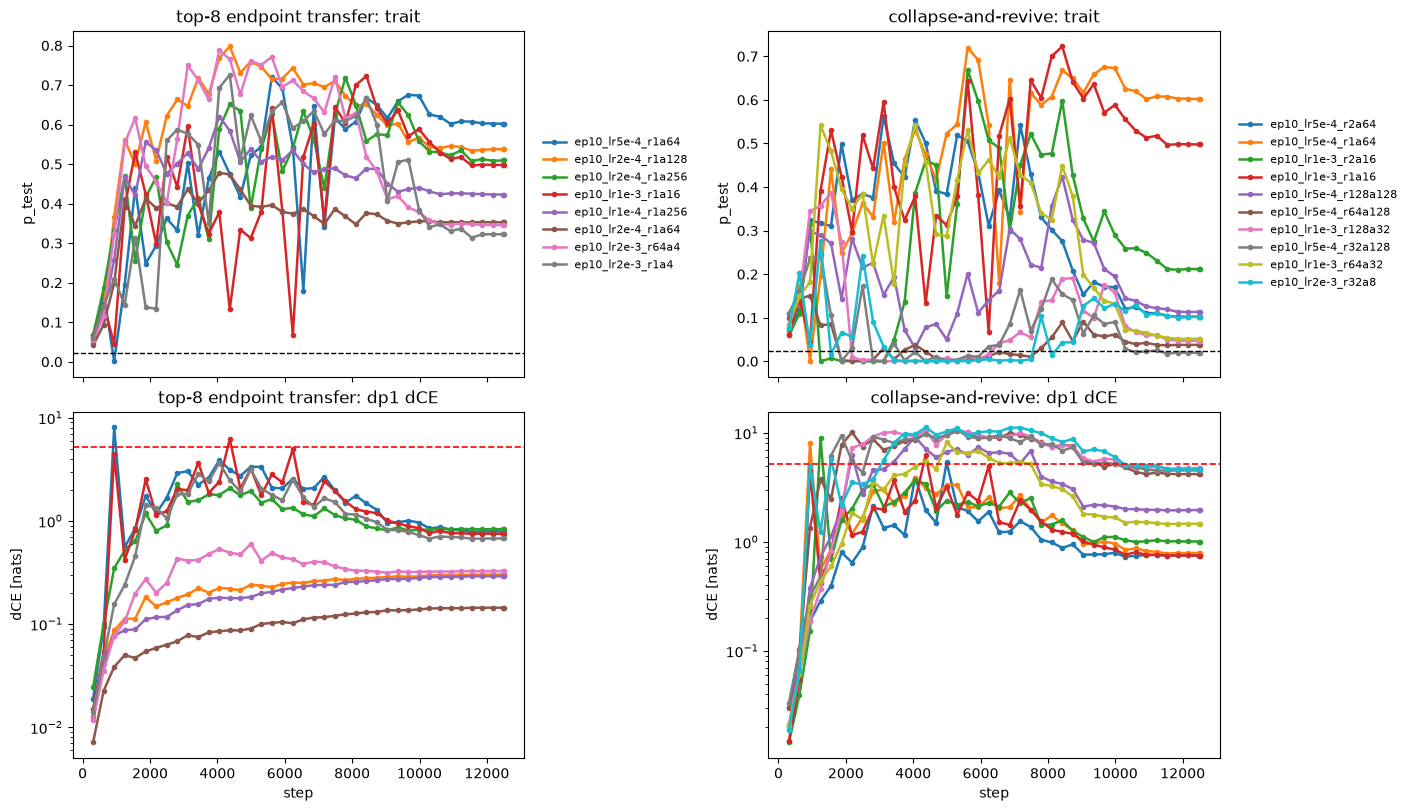

In [11]:
top = alive.sort_values("p_test", ascending=False).head(8)
rev = alive[alive["cross_step"].notna()].sort_values("K_rel")
print("top-8 endpoint transfer (alive runs):")
display(top[["tag", "K_rel", "delta_ce", "p_test", "p_off", "p_test_peak", "p_test_peak_step", "cross_step"]]
        .round(4).reset_index(drop=True))
print(f"\ncollapse-and-revive runs (crossed the cut on the trajectory, alive at the endpoint): {len(rev)}")
display(rev[["tag", "K_rel", "cross_step", "dce_peak", "dce_peak_step", "delta_ce", "p_test", "p_test_peak"]]
        .round(3).reset_index(drop=True))
print("\ndead runs: step of first crossing (of", n_steps, "):")
display(dead["cross_step"].describe().round(0).to_frame().T)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True, sharex=True)
for j, (sel, title) in enumerate([(top, "top-8 endpoint transfer"), (rev, "collapse-and-revive")]):
    pal_t = aplots.palette(list(sel["tag"]), cmap="tab10")
    for tag in sel["tag"]:
        s = tr[tr["tag"] == tag].sort_values("step")
        axes[0, j].plot(s["step"], s["p_test"], lw=1.8, marker="o", ms=3, color=pal_t[tag], label=tag)
        axes[1, j].plot(s["step"], s["delta_ce"].clip(lower=1e-3), lw=1.8, marker="o", ms=3, color=pal_t[tag], label=tag)
    axes[0, j].axhline(p0, color="k", ls="--", lw=1)
    axes[1, j].axhline(CUT, color="red", ls="--", lw=1.2)
    axes[1, j].set_yscale("log")
    axes[0, j].set_title(f"{title}: trait"); axes[1, j].set_title(f"{title}: dp1 dCE")
    axes[0, j].set_ylabel("p_test"); axes[1, j].set_ylabel("dCE [nats]"); axes[1, j].set_xlabel("step")
    aplots.right_legend(axes[0, j], fontsize=8)
plt.show()

## 5. Summary figure (exported)

Three panels: endpoint ΔCE vs K/K* with the anchored cut (collapse boundary), endpoint transfer vs
K/K* for alive runs, and trajectory-peak transfer vs K/K* for the same runs.

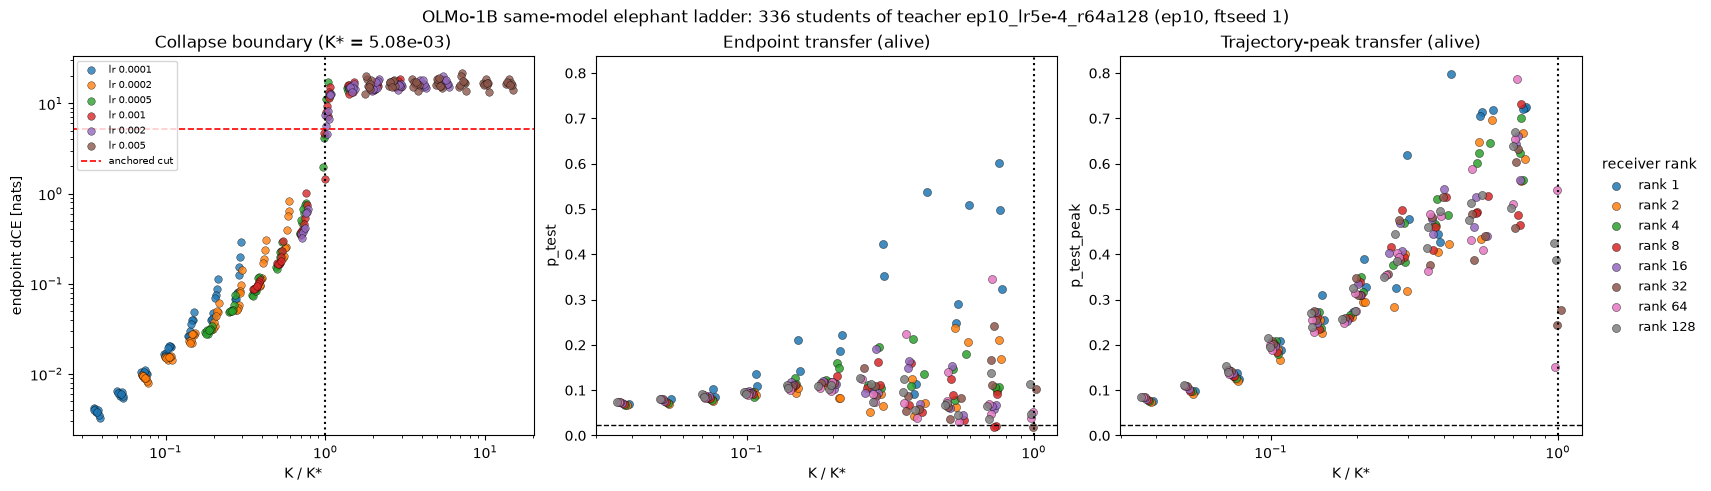

In [12]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
ax = axes[0]
for lr, sub in df.groupby("lr"):
    ax.scatter(sub["K_rel"], sub["delta_ce"].clip(lower=1e-3), s=30, alpha=0.8, color=pal[lr],
               label=f"lr {lr:g}", edgecolor="k", linewidth=0.3)
ax.axhline(CUT, ls="--", color="red", lw=1.2, label="anchored cut"); ax.axvline(1, ls=":", color="k")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("K / K*"); ax.set_ylabel("endpoint dCE [nats]")
ax.set_title(f"Collapse boundary (K* = {KSTAR_DD:.2e})"); ax.legend(fontsize=7, loc="upper left")
for ax, col, title in [(axes[1], "p_test", "Endpoint transfer (alive)"),
                       (axes[2], "p_test_peak", "Trajectory-peak transfer (alive)")]:
    for r, sub in alive.groupby("rank"):
        ax.scatter(sub["K_rel"], sub[col], s=34, alpha=0.85, color=pal_r[r], label=f"rank {r}",
                   edgecolor="k", linewidth=0.3)
    ax.axhline(p0, color="k", ls="--", lw=1); ax.axvline(1, ls=":", color="k")
    ax.set_xscale("log"); ax.set_xlabel("K / K*"); ax.set_ylabel(col); ax.set_title(title)
    ax.set_ylim(0, float(alive["p_test_peak"].max()) * 1.05)
aplots.right_legend(axes[2], title="receiver rank")
fig.suptitle("OLMo-1B same-model elephant ladder: 336 students of teacher ep10_lr5e-4_r64a128 (ep10, ftseed 1)")
fig.savefig(FIG_DIR / "dd1b_same_model_transfer.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Readout

Printed from the frames above so the prose cannot drift from the numbers.

In [13]:
r1 = alive[alive["rank"] == 1]["p_test"]; rn = alive[alive["rank"] > 1]["p_test"]
print(f"Collapse: {int(dead.shape[0])}/{len(df)} runs collapsed under the anchored dp1 cut ({CUT:.2f} nats); "
      f"K* = {KSTAR_DD:.2e} at b={B_DD:.3f}, c={C_DD:.3f} = {KSTAR_DD / cl.KSTAR_CALIBRATED:.1f}x the 160m anchor "
      f"(ep10 students vs ep20 anchors).")
print(f"Endpoint transfer (alive, n={len(alive)}): median {alive['p_test'].median():.3f}, "
      f"IQR {alive['p_test'].quantile(.25):.3f}-{alive['p_test'].quantile(.75):.3f}, max {alive['p_test'].max():.3f}; "
      f"base prior {p0:.3f}; {100 * (alive['p_test'] > 2 * p0).mean():.0f}% above 2x prior.")
print(f"  rank-1 receivers: median {r1.median():.3f} (n={len(r1)}) vs other ranks {rn.median():.3f} (n={len(rn)}).")
print(f"Trajectory: median peak {alive['p_test_peak'].median():.3f} at step "
      f"{int(alive['p_test_peak_step'].median())}/{n_steps}; {int(alive['peaks_at_end'].sum())} of {len(alive)} alive runs "
      f"peak at the final checkpoint; median peak/endpoint ratio {alive['peak_over_end'].median():.2f}.")
print(f"  {len(rev)} alive runs crossed the cut mid-training and recovered; dead runs first cross at "
      f"median step {int(dead['cross_step'].median())}.")

Collapse: 146/336 runs collapsed under the anchored dp1 cut (5.19 nats); K* = 5.08e-03 at b=0.490, c=-0.019 = 6.0x the 160m anchor (ep10 students vs ep20 anchors).
Endpoint transfer (alive, n=190): median 0.096, IQR 0.074-0.119, max 0.602; base prior 0.023; 94% above 2x prior.
  rank-1 receivers: median 0.186 (n=23) vs other ranks 0.094 (n=167).
Trajectory: median peak 0.356 at step 3120/12500; 2 of 190 alive runs peak at the final checkpoint; median peak/endpoint ratio 2.71.
  10 alive runs crossed the cut mid-training and recovered; dead runs first cross at median step 624.


## 7. The boundary law refit at every checkpoint

Same recipe as the 160m strip / 410m arm per-checkpoint refits (`collapse_law.md` §2c): at each
checkpoint step every run is labelled by its **own** dp1 ΔCE at that step (`> cut`), not by its
endpoint fate, and the law is refit on those labels.  Row unit of the table: one checkpoint step
(336 runs each).  `K* (dd exps)` holds the endpoint exponents fixed and moves only the threshold;
`b, c, K* (free)` refit everything (needs ≥ 8 dead and ≥ 8 alive at that step; MLE ratios only,
near-separation as before).  Dead-set completeness = fraction of the endpoint dead set already
over the cut at that step.

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: P

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: P

per-checkpoint refit (label = each run's own dCE at that step > cut):


' step  n_dead  dead_set_complete  n_transient_dead  kstar_fixed  kstar_fixed_rel     b      c  kstar_free  misses\n  312      50               0.34                 0     0.019076             3.75 0.497 -0.036    0.018810    10.0\n  624     114               0.78                 0     0.007483             1.47 0.501 -0.063    0.007038     8.0\n  936     131               0.89                 1     0.005905             1.16 0.483 -0.061    0.005212     6.0\n 1248     136               0.92                 1     0.005486             1.08 0.514 -0.038    0.005722     6.0\n 1560     141               0.95                 2     0.005190             1.02 0.500 -0.006    0.005564     7.0\n 1872     143               0.97                 2     0.005105             1.00 0.503 -0.007    0.005570     7.0\n 2184     146               0.97                 4     0.004921             0.97 0.509 -0.006    0.005678     5.0\n 2496     148               1.00                 2     0.004991             0.9

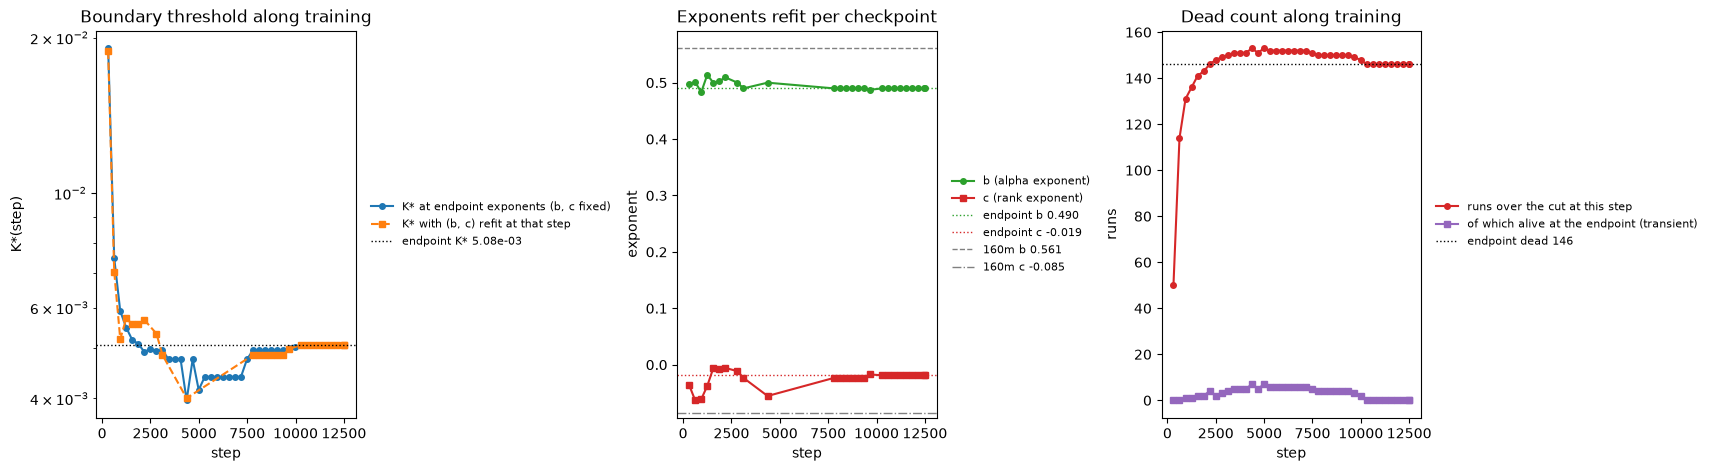

endpoint dead set 95% complete by step 1560 of 12,500; K*(fixed exps) spans 3.97e-03-1.91e-02 (4.81x) from step 312 to the end; free b range 0.483-0.514, c range -0.063--0.006.


In [14]:
lab = tr.dropna(subset=["delta_ce"]).copy()
lab["collapsed"] = (lab["delta_ce"] > CUT).astype(int)
lab["student_tag"] = lab["tag"]
end_dead = set(dead["tag"])
rows_t = []
for step, g in lab.groupby("step"):
    row = {"step": int(step), "n": len(g), "n_dead": int(g["collapsed"].sum()),
           "dead_set_complete": len(set(g.loc[g["collapsed"] == 1, "tag"]) & end_dead) / max(1, len(end_dead)),
           "n_revive_alive": int(((g["collapsed"] == 0) & g["tag"].isin(end_dead)).sum()),
           "n_transient_dead": int(((g["collapsed"] == 1) & ~g["tag"].isin(end_dead)).sum())}
    if g["collapsed"].nunique() == 2:
        row["kstar_fixed"] = cl.kstar_logistic(g, B_DD, C_DD)["kstar"]
        if row["n_dead"] >= 8 and len(g) - row["n_dead"] >= 8:
            try:
                f = cl.fit_collapse_law(g)
            except np.linalg.LinAlgError:   # perfectly separated at this step: ratios undefined
                f = None
            if f is not None and np.isfinite(f.b) and np.isfinite(f.c):
                k_free = cl.kstar_logistic(g, f.b, f.c)["kstar"]
                row.update(b=f.b, c=f.c, kstar_free=k_free, misses=cl.law_misses(g, f.b, f.c, k_free)[0])
    rows_t.append(row)
BT = pd.DataFrame(rows_t)
BT["kstar_fixed_rel"] = BT["kstar_fixed"] / KSTAR_DD
show = BT[["step", "n_dead", "dead_set_complete", "n_transient_dead", "kstar_fixed", "kstar_fixed_rel", "b", "c", "kstar_free", "misses"]]
print("per-checkpoint refit (label = each run's own dCE at that step > cut):")
display(show.round({"dead_set_complete": 2, "kstar_fixed": 6, "kstar_fixed_rel": 2, "b": 3, "c": 3, "kstar_free": 6}).to_string(index=False))

ok = BT.dropna(subset=["b"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)
ax = axes[0]
ax.plot(BT["step"], BT["kstar_fixed"], "o-", ms=4, color="tab:blue", label="K* at endpoint exponents (b, c fixed)")
ax.plot(ok["step"], ok["kstar_free"], "s--", ms=4, color="tab:orange", label="K* with (b, c) refit at that step")
ax.axhline(KSTAR_DD, color="k", ls=":", lw=1, label=f"endpoint K* {KSTAR_DD:.2e}")
ax.set_yscale("log"); ax.set_xlabel("step"); ax.set_ylabel("K*(step)"); ax.set_title("Boundary threshold along training")
aplots.right_legend(ax, fontsize=8)
ax = axes[1]
ax.plot(ok["step"], ok["b"], "o-", ms=4, color="tab:green", label="b (alpha exponent)")
ax.plot(ok["step"], ok["c"], "s-", ms=4, color="tab:red", label="c (rank exponent)")
ax.axhline(B_DD, color="tab:green", ls=":", lw=1, label=f"endpoint b {B_DD:.3f}")
ax.axhline(C_DD, color="tab:red", ls=":", lw=1, label=f"endpoint c {C_DD:.3f}")
ax.axhline(cl.B_LAW, color="gray", ls="--", lw=1, label=f"160m b {cl.B_LAW}")
ax.axhline(cl.C_LAW, color="gray", ls="-.", lw=1, label=f"160m c {cl.C_LAW}")
ax.set_xlabel("step"); ax.set_ylabel("exponent"); ax.set_title("Exponents refit per checkpoint")
aplots.right_legend(ax, fontsize=8)
ax = axes[2]
ax.plot(BT["step"], BT["n_dead"], "o-", ms=4, color="tab:red", label="runs over the cut at this step")
ax.plot(BT["step"], BT["n_transient_dead"], "s-", ms=4, color="tab:purple", label="of which alive at the endpoint (transient)")
ax.axhline(len(dead), color="k", ls=":", lw=1, label=f"endpoint dead {len(dead)}")
ax.set_xlabel("step"); ax.set_ylabel("runs"); ax.set_title("Dead count along training")
aplots.right_legend(ax, fontsize=8)
plt.show()

first = BT[BT["dead_set_complete"] >= 0.95].iloc[0]
print(f"endpoint dead set 95% complete by step {int(first['step'])} of {n_steps:,}; "
      f"K*(fixed exps) spans {BT['kstar_fixed'].min():.2e}-{BT['kstar_fixed'].max():.2e} "
      f"({BT['kstar_fixed'].max() / BT['kstar_fixed'].min():.2f}x) from step {int(BT['step'].min())} to the end; "
      f"free b range {ok['b'].min():.3f}-{ok['b'].max():.3f}, c range {ok['c'].min():.3f}-{ok['c'].max():.3f}.")